# Bước 2.5 — Dự đoán khoảng lương từ kỹ năng và kinh nghiệm
Bản hoàn chỉnh: DummyClassifier, Decision Tree có cắt tỉa, Random Forest; CV theo nhóm, đánh giá và phân tích lỗi từng tin.
Chọn mô hình bằng CV trên train; test chỉ dùng đánh giá cuối. Kết quả chỉ áp dụng cho các tin công khai lương đủ điều kiện trong tập dữ liệu.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             make_scorer)
SEED = 42
# Ưu tiên tìm CSV trong repository chứa thư mục chạy notebook.
DATA_OVERRIDE = Path(r"D:/Projects/vietnam-it-job-market-analysis-git/buoc2.1_2.2/data/processed/clean_data_processed.csv")
REL_DATA = Path("buoc2.1_2.2/data/processed/clean_data_processed.csv")
candidates = [p / REL_DATA for p in [Path.cwd(), *Path.cwd().parents]]
DATA_PATH = next((p for p in candidates if p.is_file()), DATA_OVERRIDE)
assert DATA_PATH.is_file(), f"Không tìm thấy CSV: {DATA_PATH}"
# Kết quả xuất trong thư mục chạy notebook; đường dẫn được in khi hoàn tất.
RESULT_DIR = Path.cwd() / "output_salary_final"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
for name in ["data", "figures"]:
    (RESULT_DIR / name).mkdir(exist_ok=True)
def save_table(table, name, index=False):
    table.to_csv(RESULT_DIR / "data" / name, index=index, encoding="utf-8-sig")
df = pd.read_csv(DATA_PATH, low_memory=False)
required = ["skills", "exp_min_years", "exp_max_years", "Luong_TB", "salary_eda_eligible", "job_group_id", "description_clean"]
assert set(required).issubset(df.columns), set(required) - set(df.columns)
print(DATA_PATH, df.shape)


D:\Projects\vietnam-it-job-market-analysis-git\buoc2.1_2.2\data\processed\clean_data_processed.csv (3135, 47)


## 1. Lọc mẫu và tạo nhãn
Không dùng salary_status làm nhãn khoảng lương. Không điền lương thiếu bằng trung bình.
Thống kê 761 và 168/362/231 là mốc kiểm tra của phiên bản CSV đã xem; nếu dữ liệu thay đổi phải kiểm tra lại.


In [2]:
eligible = df["salary_eda_eligible"].astype(str).str.strip().str.lower().eq("true")
salary = pd.to_numeric(df["Luong_TB"], errors="coerce")
valid = eligible & salary.notna() & np.isfinite(salary) & salary.gt(0)
data = df.loc[valid].copy().reset_index(names="source_row")
data["Luong_TB"] = salary.loc[valid].to_numpy()
LABELS = ["duoi_15", "15_den_30", "tren_30"]
data["salary_class"] = np.select(
    [data["Luong_TB"].lt(15_000_000), data["Luong_TB"].le(30_000_000)],
    LABELS[:2], default=LABELS[2])
for col in ["exp_min_years", "exp_max_years"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
    data.loc[~np.isfinite(data[col]) | data[col].lt(0), col] = np.nan
invalid_exp = data["exp_min_years"].gt(data["exp_max_years"])
assert not invalid_exp.any(), "Có khoảng kinh nghiệm đảo ngược; kiểm tra nguồn trước khi tiếp tục"
def parse_skills(value):
    if isinstance(value, list):
        values = value
    elif pd.isna(value) or str(value).strip() == "":
        values = []
    else:
        values = json.loads(value)
    if not isinstance(values, list):
        raise ValueError(f"skills phải là JSON list: {value}")
    return sorted({str(v).strip().casefold() for v in values if str(v).strip()})
# Chuẩn hóa JSON nhưng chưa học vocabulary trên toàn dữ liệu.
data["skills"] = data["skills"].apply(lambda v: json.dumps(parse_skills(v), ensure_ascii=False))
display(data["salary_class"].value_counts().reindex(LABELS))
print("Mẫu:", len(data), "; skills rỗng:", data["skills"].eq("[]").sum())
print("Kinh nghiệm thiếu:", data[["exp_min_years", "exp_max_years"]].isna().sum().to_dict())
save_table(data["salary_class"].value_counts().reindex(LABELS).rename_axis("class").reset_index(name="count"), "class_distribution.csv")


Mẫu: 761 ; skills rỗng: 108
Kinh nghiệm thiếu: {'exp_min_years': 47, 'exp_max_years': 284}


salary_class
duoi_15      168
15_den_30    362
tren_30      231
Name: count, dtype: int64

## 2. Nhóm chống rò rỉ và chia tập
Dùng thành phần liên thông: hai tin cùng ID nhóm hoặc cùng mô tả chuẩn hóa không được tách ra.
Mô tả rỗng không được gom chung. Đây là kiểm tra trùng chính xác sau chuẩn hóa; chưa phát hiện mọi mô tả gần giống.
Không gom nhóm theo X vì nhiều tin độc lập có thể cùng kỹ năng/kinh nghiệm.


In [3]:
parent = list(range(len(data)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    parent[find(a)] = find(b)
for col in ["job_group_id", "description_clean"]:
    seen = {}
    for i, value in enumerate(data[col].fillna("").astype(str)):
        key = " ".join(value.casefold().split())
        if not key:
            continue
        if key in seen:
            union(i, seen[key])
        else:
            seen[key] = i
groups = pd.Series([find(i) for i in range(len(data))], index=data.index)
FEATURES = ["skills", "exp_min_years", "exp_max_years"]
X, y = data[FEATURES].copy(), data["salary_class"].copy()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert not set(g_train) & set(g_test)
assert set(y_train) == set(LABELS) == set(y_test)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
# Danh sách fold cố định dùng chung cho TẤT CẢ mô hình.
folds = list(cv.split(X_train, y_train, g_train))
fold_rows = []
for k, (tr, va) in enumerate(folds, 1):
    assert not set(g_train.iloc[tr]) & set(g_train.iloc[va])
    assert set(y_train.iloc[tr]) == set(LABELS) == set(y_train.iloc[va])
    for split, ids in [("train", tr), ("validation", va)]:
        for label in LABELS:
            fold_rows.append({"fold": k, "split": split, "class": label,
                              "n": int(y_train.iloc[ids].eq(label).sum())})
save_table(pd.DataFrame(fold_rows), "fold_distribution.csv")
split_manifest = data[["source_row", "job_uid", "salary_class"]].copy()
split_manifest["group"] = groups
split_manifest["split"] = "train"
split_manifest.loc[test_idx, "split"] = "test"
save_table(split_manifest, "split_manifest.csv")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).reindex(LABELS))
print("Không có nhóm trùng giữa train/test và giữa train/validation.")


Không có nhóm trùng giữa train/test và giữa train/validation.


,train,test
salary_class,,
duoi_15,134,34
15_den_30,290,72
tren_30,184,47


## 3. Pipeline và tối ưu mô hình
Mã hóa kỹ năng thành multi-hot, giữ nguyên tên kỹ năng nhiều từ; điền kinh nghiệm thiếu trong từng fold.
GridSearchCV fit toàn bộ pipeline trong fold nên vocabulary và median không học từ validation/test.
Decision Tree khảo sát cả alpha=0 và alpha>0. Nếu CV chọn alpha=0, không tuyên bố mô hình tốt nhất đã cắt tỉa;
notebook xuất thêm cây có alpha>0 tốt nhất theo CV để chứng minh thí nghiệm cắt tỉa.


In [4]:
def preprocessing():
    return ColumnTransformer([
        ("skills", CountVectorizer(analyzer=parse_skills, binary=True), "skills"),
        ("experience", SimpleImputer(strategy="median", add_indicator=True),
         ["exp_min_years", "exp_max_years"])
    ])
def pipeline(model):
    return Pipeline([("features", preprocessing()), ("model", model)])
macro = make_scorer(f1_score, labels=LABELS, average="macro", zero_division=0)
specs = {
    "Dummy": (DummyClassifier(strategy="most_frequent"), {}),
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED, class_weight="balanced"), {
        "model__max_depth": [3, 6, None],
        "model__min_samples_leaf": [3, 10],
        "model__ccp_alpha": [0.0, 0.001, 0.01]}),
    "RandomForest": (RandomForestClassifier(random_state=SEED, n_jobs=1,
                                            class_weight="balanced_subsample"), {
        "model__n_estimators": [200],
        "model__max_depth": [6, None],
        "model__min_samples_leaf": [2, 5, 10]})}
searches = {}
for name, (model, params) in specs.items():
    search = GridSearchCV(pipeline(model), params, scoring=macro, cv=folds,
                          n_jobs=2, return_train_score=True, error_score="raise", refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    save_table(pd.DataFrame(search.cv_results_), f"cv_{name}.csv")
    print(name, search.best_score_, search.best_params_)
# Chọn trước khi xem các kết quả test.
winner_name = max(searches, key=lambda name: searches[name].best_score_)
winner = searches[winner_name].best_estimator_
print("Mô hình được chọn bằng CV:", winner_name)


Dummy 0.21529295181469096 {}
DecisionTree 0.6105829609201575 {'model__ccp_alpha': 0.001, 'model__max_depth': 6, 'model__min_samples_leaf': 10}
RandomForest 0.6396091345834368 {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Mô hình được chọn bằng CV: RandomForest


## 4. Đánh giá chung và overfitting
Train là điểm fit lại trên toàn train, không phải ước lượng tổng quát hóa.
Gap lớn là tín hiệu overfitting; so sánh thêm điểm train/validation theo CV và độ lệch chuẩn qua fold.
Không bảo đảm đổi nhãn hoặc cắt tỉa sẽ làm Macro F1 tăng.


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,train_macro_f1,gap,cv_macro_f1,cv_train_macro_f1,cv_std
0,Dummy,0.470588,0.156863,0.333333,0.213333,0.301176,0.215293,0.001960,0.215293,0.215293,0.000929
1,DecisionTree,0.627451,0.623973,0.660988,0.630381,0.623515,0.659482,0.029100,0.610583,0.656651,0.043228
2,RandomForest,0.666667,0.659392,0.680133,0.666407,0.666988,0.805235,0.138828,0.639609,0.808798,0.024048


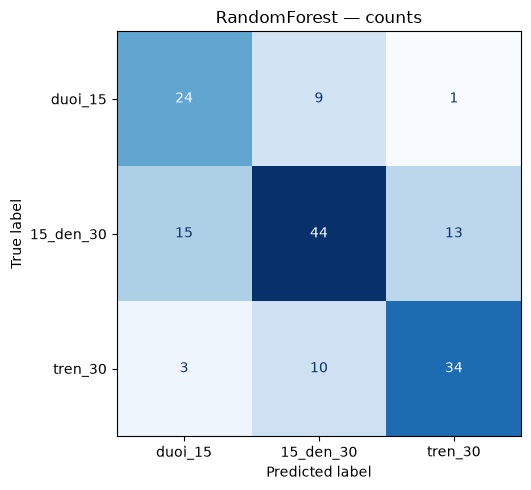

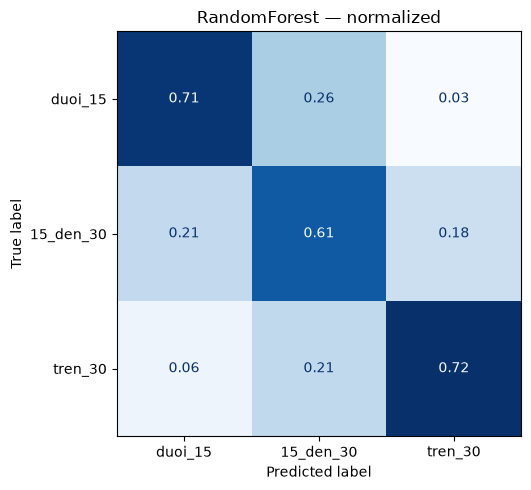

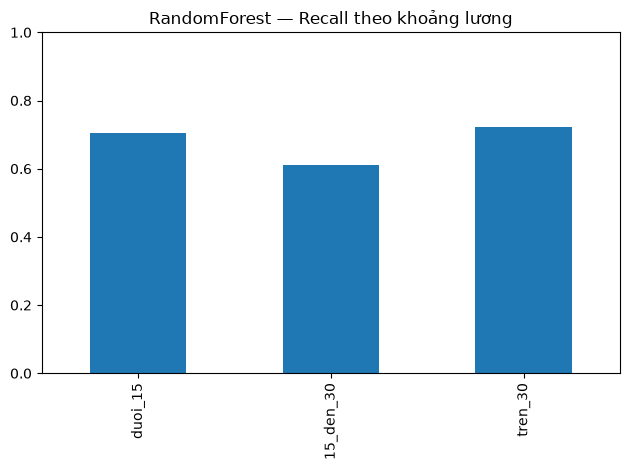

In [5]:
rows = []
for name, search in searches.items():
    model = search.best_estimator_
    pt, pv = model.predict(X_train), model.predict(X_test)
    train_f1 = f1_score(y_train, pt, labels=LABELS, average="macro", zero_division=0)
    test_f1 = f1_score(y_test, pv, labels=LABELS, average="macro", zero_division=0)
    b = search.best_index_
    rows.append({"model": name,
        "accuracy": accuracy_score(y_test, pv),
        "macro_precision": precision_score(y_test, pv, labels=LABELS, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, pv, labels=LABELS, average="macro", zero_division=0),
        "macro_f1": test_f1, "weighted_f1": f1_score(y_test, pv, average="weighted", zero_division=0),
        "train_macro_f1": train_f1, "gap": train_f1-test_f1,
        "cv_macro_f1": search.best_score_,
        "cv_train_macro_f1": search.cv_results_["mean_train_score"][b],
        "cv_std": search.cv_results_["std_test_score"][b]})
    report = pd.DataFrame(classification_report(y_test, pv, labels=LABELS,
                                              output_dict=True, zero_division=0)).T
    save_table(report, f"classification_report_{name}.csv", index=True)
comparison = pd.DataFrame(rows)
save_table(comparison, "model_comparison.csv")
display(comparison)
pred = winner.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=LABELS)
assert cm.sum() == len(y_test)
assert cm.trace() == (pred == y_test.to_numpy()).sum()
save_table(pd.DataFrame(cm, index=LABELS, columns=LABELS), "confusion_matrix.csv", index=True)
for norm, suffix in [(None, "counts"), ("true", "normalized")]:
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, normalize=norm,
        ax=ax, cmap="Blues", values_format="d" if norm is None else ".2f", colorbar=False)
    ax.set_title(f"{winner_name} — {suffix}")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / "figures" / f"confusion_{suffix}.png", dpi=160)
    plt.show()
report = pd.DataFrame(classification_report(y_test, pred, labels=LABELS, output_dict=True, zero_division=0)).T
save_table(report.loc[LABELS], "recall_by_class.csv", index=True)
ax = report.loc[LABELS, "recall"].plot.bar(ylim=(0, 1), title=f"{winner_name} — Recall theo khoảng lương")
ax.figure.tight_layout()
ax.figure.savefig(RESULT_DIR / "figures" / "recall_by_class.png", dpi=160)
plt.show()


## 5. Bằng chứng cắt tỉa và phân tích từng tin sai
Đồ thị cây giới hạn ba tầng chỉ để đọc hình; thống kê depth/leaves mới phản ánh toàn bộ cây.
Sai lệch hai bậc (dưới 15 ↔ trên 30) được ưu tiên trước; tiếp theo là xác suất sai cao.
Xác suất là điểm mô hình chưa hiệu chỉnh, không phải độ tin cậy đã được kiểm định.
Lương thật và mô tả chỉ được đưa vào bảng kiểm tra SAU dự đoán, không vào X.


Cây có cắt tỉa: {'model__ccp_alpha': 0.001, 'model__max_depth': 6, 'model__min_samples_leaf': 10} depth= 6 leaves= 24


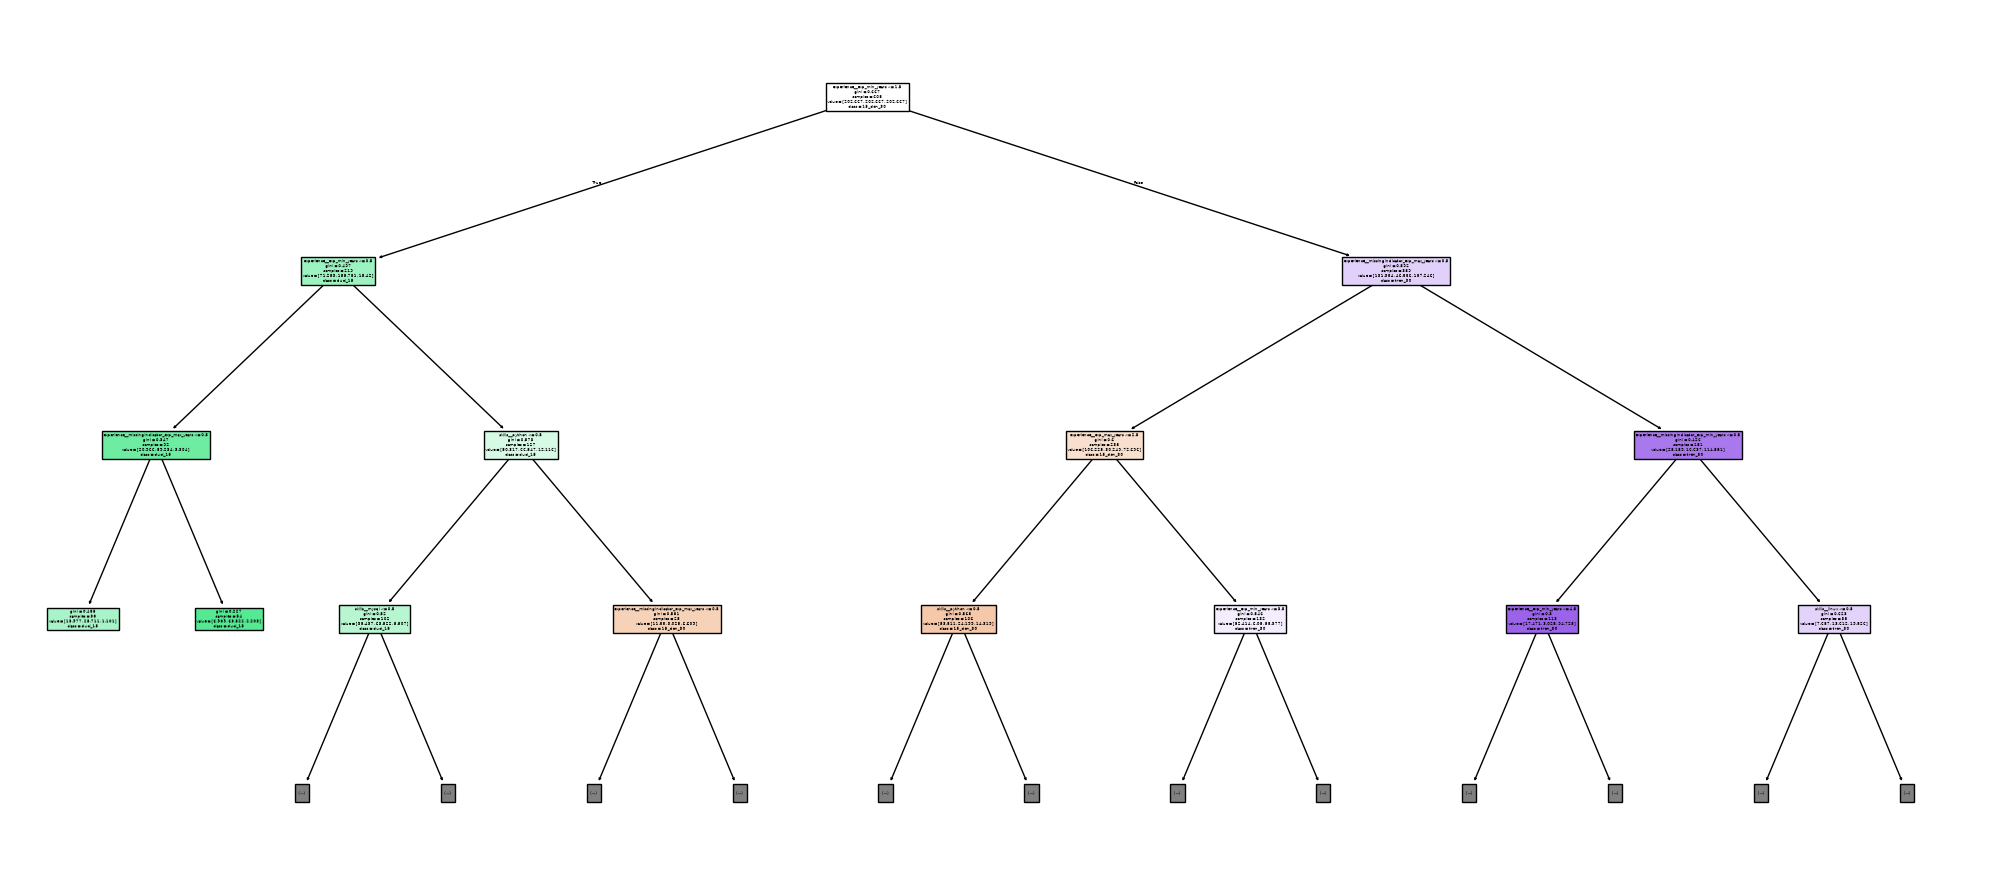

,source_row,job_uid,title,source,URL_Goc,skills,exp_min_years,exp_max_years,Luong_TB,true_class,pred_class,confidence,ordinal_error,analysis_note
644,2518,topcv-12d1a0998c,Nhân Viên Phát Triển Phần Mềm &Kỹ Thuật Viễn T...,topcv,https://www.topcv.vn/viec-lam/nhan-vien-phat-t...,[],1.0,1.0,40000000.0,tren_30,duoi_15,0.671078,2,
103,475,itviec-9c2149df10,Intern C/C++ Embedded & Systems Engineer (Qt),itviec,https://itviec.com/it-jobs/intern-c-c-embedded...,"[""bash"", ""c"", ""c++"", ""linux"", ""python""]",NaN,NaN,7637500.0,duoi_15,tren_30,0.446178,2,
672,2680,vietnamworks-b53c93b245,Kỹ Sư Triển Khai - Làm Việc Tại Hồ Chí Minh/ P...,vietnamworks,https://www.vietnamworks.com/ky-su-trien-khai-...,"[""autocad"", ""cisco"", ""cybersecurity""]",NaN,NaN,33333333.0,tren_30,duoi_15,0.410737,2,
755,3107,vietnamworks-a542956454,Software Product Owner,vietnamworks,https://www.vietnamworks.com/software-product-...,"[""agile"", ""jira"", ""scrum""]",1.0,NaN,31250000.0,tren_30,duoi_15,0.355620,2,
146,1271,topcv-80382eed9b,"Technical Support Engineer (Fixed Night Shift,...",topcv,https://www.topcv.vn/viec-lam/technical-suppor...,[],0.0,NaN,29000000.0,15_den_30,duoi_15,0.786947,1,
345,1802,topcv-230b94cd18,Nhân Viên Kỹ Sư Xây Dựng,topcv,https://www.topcv.vn/viec-lam/nhan-vien-ky-su-...,"[""autocad""]",0.0,NaN,17500000.0,15_den_30,duoi_15,0.746762,1,
454,2038,topcv-05e371f665,Nhân Viên Tư Vấn Công Nghệ Thông Tin Thu Nhập ...,topcv,https://www.topcv.vn/viec-lam/nhan-vien-tu-van...,"[""crm""]",0.0,NaN,17500000.0,15_den_30,duoi_15,0.741643,1,
245,1569,topcv-b8ff9e43ae,Data Engineer (Lead),topcv,https://www.topcv.vn/viec-lam/data-engineer-le...,"[""airflow"", ""aws"", ""azure"", ""google cloud"", ""h...",3.0,3.0,30000000.0,15_den_30,tren_30,0.715927,1,
604,2406,topcv-9bf44d7275,UI/UX Designer,topcv,https://www.topcv.vn/viec-lam/ui-ux-designer/1...,"[""figma""]",1.0,1.0,18750000.0,15_den_30,duoi_15,0.698307,1,
526,2231,topcv-55271b71d6,Business Analyst - Thu Nhập Hấp Dẫn Upto 40M -...,topcv,https://www.topcv.vn/viec-lam/business-analyst...,"[""agile"", ""figma"", ""jira"", ""llm"", ""postman"", ""...",2.0,2.0,35000000.0,tren_30,15_den_30,0.680634,1,


In [6]:
dt_search = searches["DecisionTree"]
cv_dt = pd.DataFrame(dt_search.cv_results_)
pruned_rows = cv_dt[cv_dt["param_model__ccp_alpha"].astype(float).gt(0)]
pruned_params = pruned_rows.loc[pruned_rows["mean_test_score"].idxmax(), "params"]
from sklearn.base import clone
pruned = clone(dt_search.estimator).set_params(**pruned_params).fit(X_train, y_train)
tree = pruned.named_steps["model"]
print("Cây có cắt tỉa:", pruned_params, "depth=", tree.get_depth(), "leaves=", tree.get_n_leaves())
save_table(pd.DataFrame([{"params": json.dumps(pruned_params), "depth": tree.get_depth(),
                         "leaves": tree.get_n_leaves()}]), "pruned_tree_structure.csv")
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(tree, max_depth=3, filled=True, class_names=list(tree.classes_), ax=ax,
          feature_names=list(pruned.named_steps["features"].get_feature_names_out()))
fig.tight_layout()
fig.savefig(RESULT_DIR / "figures" / "pruned_tree_top_levels.png", dpi=140)
plt.show()
review_columns = [c for c in ["source_row", "job_uid", "title", "source", "URL_Goc", "skills",
    "exp_min_years", "exp_max_years", "Luong_TB", "description_clean"] if c in data]
audit = data.iloc[test_idx][review_columns].copy()
audit["true_class"] = y_test.to_numpy()
audit["pred_class"] = pred
audit["confidence"] = winner.predict_proba(X_test).max(axis=1)
rank = {label: i for i, label in enumerate(LABELS)}
audit["ordinal_error"] = (audit["true_class"].map(rank)-audit["pred_class"].map(rank)).abs()
audit["analysis_note"] = ""  # Bổ sung nhận xét sau khi đọc từng tin, không tự suy diễn nguyên nhân.
save_table(audit, "test_predictions.csv")
errors = audit[audit["true_class"] != audit["pred_class"]].sort_values(
    ["ordinal_error", "confidence"], ascending=False)
save_table(errors, "misclassified_jobs.csv")
pairs = errors.groupby(["true_class", "pred_class"]).size().reset_index(name="count").sort_values("count", ascending=False)
save_table(pairs, "top_confusion_pairs.csv")
display(errors.drop(columns=["description_clean"], errors="ignore").head(10))


## 6. Cấu hình, kết luận và phân tích lỗi
Xuất MiniNote theo kết quả thực tế; ghi nhận bằng chứng và giả thuyết cho các tin sai đã kiểm tra.


In [7]:
config = {
    "data_path": str(DATA_PATH.resolve()),
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "sklearn": sklearn.__version__,
    "seed": SEED, "features": FEATURES,
    "target": "salary_class", "salary_unit": "VND/month; verify upstream normalization",
    "boundaries": "<15000000; 15000000<=x<=30000000; >30000000",
    "samples": len(data), "train": len(train_idx), "test": len(test_idx),
    "grouping": "connected components of job_group_id or normalized description",
    "outer_split": "first fold of StratifiedGroupKFold(5,shuffle=True,random_state=42)",
    "inner_split": "shared materialized StratifiedGroupKFold(3,shuffle=True,random_state=42)",
    "winner_selected_by": "train CV macro F1", "winner": winner_name,
    "best_params": {name: search.best_params_ for name, search in searches.items()},
    "pruned_tree_params": pruned_params,
}
(RESULT_DIR / "experiment_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# Ghi nhận bằng chứng theo từng tin; chỉ bổ sung nhận xét nếu tin thực sự sai trong lần chạy này.
review_notes = {
    "topcv-12d1a0998c": "Skills rỗng, kinh nghiệm 1/1 năm; JD có điện tử, viễn thông, quang học và yêu cầu ngoại ngữ. Giả thuyết: bộ trích kỹ năng bỏ sót miền chuyên môn nên X chưa đủ thông tin. Cần rà từ điển kỹ năng, không sửa nhãn theo dự đoán.",
    "itviec-9c2149df10": "Thiếu cả min/max kinh nghiệm; kỹ năng C/C++, Linux, Python, Bash. Tiêu đề và JD nói thực tập/sinh viên hoặc mới tốt nghiệp. Giả thuyết: X thiếu tín hiệu kinh nghiệm và kỹ năng chồng lấn với việc trình độ cao. Không tự gán 0 năm chỉ vì giá trị thiếu.",
    "vietnamworks-b53c93b245": "Thiếu min/max kinh nghiệm; JD có ICT/ELV, CCNA/CCNP, trong khi skills hiện có AutoCAD/Cisco/Cybersecurity. JD ghi thu nhập 350–450 triệu/năm, trung bình /12 khớp 33.333333 triệu/tháng. Cần phân biệt thu nhập với lương cơ bản; đây chưa phải bằng chứng nguyên nhân duy nhất của lỗi.",
    "vietnamworks-a542956454": "Kinh nghiệm tối thiểu 1 năm, tối đa thiếu; skills Agile/Jira/Scrum. JD Product Owner yêu cầu tiếng Anh, phối hợp stakeholder và quản lý backlog. Giả thuyết: kỹ năng nghiệp vụ và mức trách nhiệm chưa được X phản ánh đủ. Cần rà bộ trích kỹ năng nghiệp vụ ở thử nghiệm tiếp theo."
}
errors["analysis_note"] = errors["job_uid"].map(review_notes).fillna("")
save_table(errors, "misclassified_jobs.csv")
reviewed = errors[errors["analysis_note"].ne("")]
summary = comparison.to_string(index=False, float_format=lambda v: f"{v:.4f}")
lines = ["BƯỚC 2.5 — DỰ ĐOÁN KHOẢNG LƯƠNG", "",
    f"Nguồn: {DATA_PATH.resolve()}",
    f"Dữ liệu gốc: {len(df)}; đủ điều kiện: {len(data)}; train: {len(train_idx)}; test: {len(test_idx)}.",
    "Nhãn: <15 triệu; 15–30 triệu gồm hai đầu; >30 triệu. Đơn vị mục tiêu VND/tháng, cần đối chiếu quy tắc chuẩn hóa đầu nguồn.",
    f"Phân bố: {data['salary_class'].value_counts().to_dict()}",
    "X chỉ gồm skills, exp_min_years, exp_max_years. Lương, tiêu đề và mô tả không vào X.",
    "Kỹ năng multi-hot; median và chỉ báo thiếu học trong pipeline từng fold.",
    "Nhóm là thành phần liên thông của job_group_id hoặc mô tả chuẩn hóa giống nhau; không có nhóm giao nhau train/test hoặc train/validation.",
    "Chưa phát hiện hết tin gần trùng. Ba mô hình dùng chung 3 fold CV trên train.",
    f"Chọn mô hình bằng CV Macro F1: {winner_name}. Không chọn lại bằng test.", "", summary, "",
    f"Cây cắt tỉa: {pruned_params}; độ sâu {tree.get_depth()}, số lá {tree.get_n_leaves()}.",
    "CV tìm cả alpha=0 và alpha>0. Nếu cấu hình DT tốt nhất có alpha=0, cây cắt tỉa bổ sung không được gọi là DT tốt nhất.",
    "Train là điểm fit lại trên toàn train; gap lớn cảnh báo overfitting. So sánh thêm CV train/validation và độ lệch chuẩn, không chỉ test.",
    "", "PHÂN TÍCH TIN SAI CỤ THỂ"]
for _, row in reviewed.iterrows():
    lines += ["", f"{row['job_uid']} — {row['title']}",
        f"Thật: {row['true_class']}; dự đoán: {row['pred_class']}; lương: {row['Luong_TB']:,.0f} VND/tháng.",
        f"Skills: {row['skills']}; kinh nghiệm min/max: {row['exp_min_years']}/{row['exp_max_years']}.",
        row["analysis_note"]]
lines += ["", "HẠN CHẾ VÀ HƯỚNG PHÁT TRIỂN",
    "Kết quả chỉ phản ánh tin công khai lương đủ điều kiện, chưa đại diện toàn bộ thị trường. Lương/thu nhập, quy đổi ngoại tệ/kỳ lương và nhãn gần ngưỡng cần được kiểm tra từ dữ liệu gốc.",
    "Các nguyên nhân lỗi là giả thuyết dựa trên JD. Không sửa extractor hoặc tham số dựa test hiện tại rồi coi điểm test đó là đánh giá độc lập mới; dùng tập kiểm tra mới hoặc nested CV khi đánh giá phiên bản sau.",
    "Cần cải thiện độ đầy đủ của skills/experience bằng quy tắc chung; không đưa cột lương hay văn bản chứa lương vào X để tăng điểm.",
    "Bước này kế thừa dữ liệu processed của 2.1–2.2. Chưa kiểm tra kết quả Clustering/Apriori trong lần này nên không tự tạo liên hệ định lượng với 2.3–2.4.",
    "", "TÁI LẬP",
    "Restart & Run All từ kernel sạch. Xem experiment_config.json để đối chiếu seed, phiên bản thư viện, hash CSV và cấu hình; split_manifest.csv để kiểm tra chia tập.",
    "Bảng/hình đều được tính từ cùng lần chạy. Điểm có thể thay đổi khi đổi dữ liệu hoặc phiên bản thư viện."]
report_text = "\n".join(lines)
(RESULT_DIR / "MiniNote_salary_final.txt").write_text(report_text, encoding="utf-8")
print(report_text)
print("\nĐã xuất kết quả:", RESULT_DIR.resolve())
display(reviewed[["job_uid", "true_class", "pred_class", "Luong_TB", "analysis_note"]])


BƯỚC 2.5 — DỰ ĐOÁN KHOẢNG LƯƠNG

Nguồn: D:\Projects\vietnam-it-job-market-analysis-git\buoc2.1_2.2\data\processed\clean_data_processed.csv
Dữ liệu gốc: 3135; đủ điều kiện: 761; train: 608; test: 153.
Nhãn: <15 triệu; 15–30 triệu gồm hai đầu; >30 triệu. Đơn vị mục tiêu VND/tháng, cần đối chiếu quy tắc chuẩn hóa đầu nguồn.
Phân bố: {'15_den_30': 362, 'tren_30': 231, 'duoi_15': 168}
X chỉ gồm skills, exp_min_years, exp_max_years. Lương, tiêu đề và mô tả không vào X.
Kỹ năng multi-hot; median và chỉ báo thiếu học trong pipeline từng fold.
Nhóm là thành phần liên thông của job_group_id hoặc mô tả chuẩn hóa giống nhau; không có nhóm giao nhau train/test hoặc train/validation.
Chưa phát hiện hết tin gần trùng. Ba mô hình dùng chung 3 fold CV trên train.
Chọn mô hình bằng CV Macro F1: RandomForest. Không chọn lại bằng test.

       model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  train_macro_f1    gap  cv_macro_f1  cv_train_macro_f1  cv_std
       Dummy    0.4706         

,job_uid,true_class,pred_class,Luong_TB,analysis_note
644,topcv-12d1a0998c,tren_30,duoi_15,40000000.0,"Skills rỗng, kinh nghiệm 1/1 năm; JD có điện t..."
103,itviec-9c2149df10,duoi_15,tren_30,7637500.0,"Thiếu cả min/max kinh nghiệm; kỹ năng C/C++, L..."
672,vietnamworks-b53c93b245,tren_30,duoi_15,33333333.0,"Thiếu min/max kinh nghiệm; JD có ICT/ELV, CCNA..."
755,vietnamworks-a542956454,tren_30,duoi_15,31250000.0,"Kinh nghiệm tối thiểu 1 năm, tối đa thiếu; ski..."
